# Практическая работа №6
## Классификация текстов — Вариант B

**Датасет:** SMS Spam Collection

**Цель:** научиться очищать текст, удалять стоп-слова, выполнять токенизацию и преобразовывать сообщения в числовые признаки с помощью TF-IDF.

**Задача:** определить, является SMS-сообщение спамом или обычным сообщением.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import string

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv(
    "../data/sms_spam.tsv",
    sep="\t",
    header=None,
    names=["label", "text"],
    encoding="utf-8"
)

display(df.head())

print("Размер датасета:", df.shape)
print("\nКоличество сообщений по классам:")
print(df["label"].value_counts())

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Размер датасета: (5572, 2)

Количество сообщений по классам:
label
ham     4825
spam     747
Name: count, dtype: int64


In [3]:
print("Пропущенные значения:")
print(df.isnull().sum())

print("\nПовторяющиеся строки:")
print(df.duplicated().sum())

Пропущенные значения:
label    0
text     0
dtype: int64

Повторяющиеся строки:
403


### Первичный анализ данных

Датасет состоит из SMS-сообщений, разделённых на две категории: ham (обычные сообщения) и spam (нежелательные рекламные сообщения).

Целевой переменной является label, а текст сообщения содержится в text.

Перед обучением необходимо очистить текст от лишних символов, выполнить токенизацию и преобразовать слова в числовое представление.

In [4]:
stop_words = set(ENGLISH_STOP_WORDS) - {
    "no", "not", "nor"
}

def clean_text(text):
    text = str(text).lower()

    text = re.sub(r"\d+", " ", text)

    text = re.sub(
        f"[{re.escape(string.punctuation)}]",
        " ",
        text
    )

    tokens = re.findall(r"[a-z]+", text)

    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    return " ".join(tokens)

In [5]:
example = "FREE Prize!!! Call 12345 NOW to win money!"

example_clean = clean_text(example)
tokens = example_clean.split()

print("Исходный текст:", example)
print("Очищенный текст:", example_clean)
print("Токены:", tokens)

Исходный текст: FREE Prize!!! Call 12345 NOW to win money!
Очищенный текст: free prize win money
Токены: ['free', 'prize', 'win', 'money']


### Предобработка текста

Создана функция clean_text(), которая переводит текст в нижний регистр, удаляет цифры, знаки пунктуации и стоп-слова.

Токенизация выполняется выделением английских слов из текста. Для отрицаний сделано исключение, поскольку они могут влиять на смысл.

Стемминг и лемматизация не используются, чтобы сохранить исходные формы значимых слов.

In [6]:
X = df["text"]
y = df["label"].map({
    "ham": 0,
    "spam": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", len(X_train))
print("Test:", len(X_test))

Train: 4457
Test: 1115


### Разделение данных

Данные разделены на обучающую выборку (80%) и тестовую выборку (20%).

Используется стратификация, чтобы сохранить соотношение обычных сообщений и спама.

Векторизатор будет обучаться только на тренировочной выборке, чтобы избежать утечки информации.

In [7]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        preprocessor=clean_text,
        tokenizer=str.split,
        token_pattern=None,
        lowercase=False,
        min_df=2,
        max_df=0.95,
        max_features=3000
    )),
    ("classifier", MultinomialNB())
])

model.fit(X_train, y_train)

print("Модель успешно обучена!")

Модель успешно обучена!


In [8]:
vectorizer = model.named_steps["tfidf"]

X_train_tfidf = vectorizer.transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Train:", X_train_tfidf.shape)
print("Test:", X_test_tfidf.shape)

print("Размер словаря:",
      len(vectorizer.get_feature_names_out()))

Train: (4457, 3000)
Test: (1115, 3000)
Размер словаря: 3000


### TF-IDF векторизация

Для преобразования текста используется TfidfVectorizer с ограничением словаря.

Редкие слова, встречающиеся менее чем в двух обучающих сообщениях, исключаются. Максимальное количество признаков ограничено 3000.

Векторизатор обучается только на train. Для test используется transform(), поэтому словарь и количество столбцов остаются одинаковыми.

In [9]:
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1:", round(f1_score(y_test, y_pred), 3))

print("\nПолный отчет:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

Accuracy: 0.975
Precision: 0.992
Recall: 0.819
F1: 0.897

Полный отчет:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.99       966
        Spam       0.99      0.82      0.90       149

    accuracy                           0.97      1115
   macro avg       0.98      0.91      0.94      1115
weighted avg       0.98      0.97      0.97      1115



### Оценка качества модели

Для оценки классификатора используются Accuracy, Precision, Recall и F1.

Accuracy показывает долю правильных ответов.

Precision показывает, какая доля сообщений, распознанных как спам, действительно является спамом.

Recall показывает, какую долю настоящего спама модель смогла обнаружить.

F1 объединяет Precision и Recall и помогает оценивать модель при дисбалансе классов.

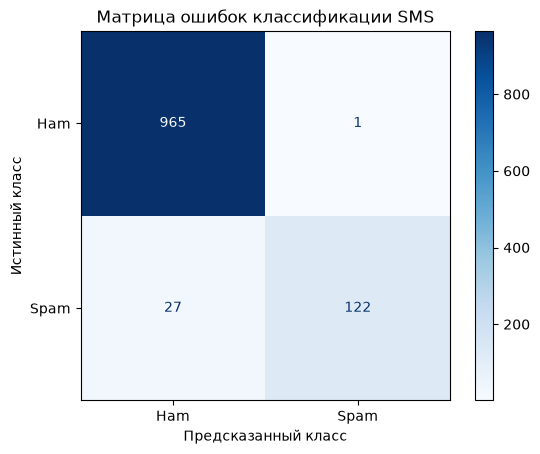

In [10]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues")

plt.title("Матрица ошибок классификации SMS")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.show()

In [11]:
results = pd.DataFrame({
    "Text": X_test,
    "True": y_test,
    "Predicted": y_pred
})

errors = results[
    results["True"] != results["Predicted"]
]

print("Количество ошибок:", len(errors))

display(errors.head(5))

Количество ошибок: 28


,Text,True,Predicted
5,FreeMsg Hey there darling it's been 3 week's n...,1,0
3750,Dear Voucher Holder 2 claim your 1st class air...,1,0
856,Talk sexy!! Make new friends or fall in love i...,1,0
1663,Hi if ur lookin 4 saucy daytime fun wiv busty ...,1,0
3981,ringtoneking 84484,1,0


In [12]:
for i, (_, row) in enumerate(errors.head(5).iterrows(), 1):
    print(f"\nОшибка {i}")
    print("Сообщение:", row["Text"])
    print("Реальный класс:", "Spam" if row["True"] == 1 else "Ham")
    print("Предсказание:", "Spam" if row["Predicted"] == 1 else "Ham")



Ошибка 1
Сообщение: FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
Реальный класс: Spam
Предсказание: Ham

Ошибка 2
Сообщение: Dear Voucher Holder 2 claim your 1st class airport lounge passes when using Your holiday voucher call 08704439680. When booking quote 1st class x 2
Реальный класс: Spam
Предсказание: Ham

Ошибка 3
Сообщение: Talk sexy!! Make new friends or fall in love in the worlds most discreet text dating service. Just text VIP to 83110 and see who you could meet.
Реальный класс: Spam
Предсказание: Ham

Ошибка 4
Сообщение: Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sort time 09099726429 JANINExx Calls£1/minMobsmoreLKPOBOX177HP51FL
Реальный класс: Spam
Предсказание: Ham

Ошибка 5
Сообщение: ringtoneking 84484
Реальный класс: Spam
Предсказание: Ham


### Анализ ошибок классификатора

При анализе неправильно классифицированных сообщений проверяются следующие возможные причины:

1. **Неоднозначные слова.** Некоторые обычные сообщения содержат слова, характерные для спама.

2. **Удаление цифр.** Телефонные номера и суммы денежных призов могут быть важными признаками спама, но удаляются при очистке.

3. **Слишком короткие сообщения.** В них мало слов, поэтому модели сложно определить класс.

4. **Редкие слова.** Некоторые важные слова отсутствуют в словаре TF-IDF из-за ограничения min_df.

5. **Необычное написание.** Сокращения, ошибки и нестандартные выражения могут мешать классификации.

Эти объяснения являются гипотезами. Для окончательного анализа необходимо сопоставить каждую причину с конкретным ошибочно классифицированным сообщением.

## Итоговый отчёт

1. В практической работе использован датасет SMS Spam Collection с обычными сообщениями и спамом.

2. Реализована функция очистки текста: нижний регистр, удаление пунктуации, цифр и стоп-слов.

3. Проведена токенизация. Для векторизации используется TF-IDF с ограничением словаря.

4. Обучен классификатор Multinomial Naive Bayes в составе Pipeline.

5. Данные разделены на train и test до обучения векторизатора. Это предотвращает утечку информации.

6. Качество модели оценивается через Accuracy, Precision, Recall и F1. Построена матрица ошибок.

7. Выполнен анализ ошибочно классифицированных сообщений. Возможные причины ошибок включают потерю полезной информации при очистке и наличие редких слов.

### Заключение

TF-IDF и наивный байесовский классификатор позволяют решать задачу классификации коротких текстов. Качество зависит не только от алгоритма, но и от способов очистки текста, состава словаря и распределения классов.